<div style="display: flex; justify-content: space-between; align-items: flex-start; border-bottom: 2px solid #555555; padding-bottom: 15px; margin-bottom: -8px;">
    <div style="width: 50%;">
        <h2>
            <span style="color: #B30033;">▍</span>TRABAJO DE FIN DE MÁSTER
        </h2>
        <h1 style="margin-top: -10px;">
            Creación de un framework para recomendar las personas más adecuadas para trabajar en un determinado proyecto de ingeniería del software
        </h1>
    </div>
    <div style="width: 50%; text-align: right;">
        <div style="display: flex; justify-content: space-between; align-items: flex-start; margin-top: 30px;">
            <div style="width: 20%;"></div>
            <div style="width: 80%; border-left: 2px solid #555555; padding-left: 20px;">
                <div style="margin-bottom: 20px;">
                    <p style="margin: 0; font-size: 1.4em; font-weight: bold;">
                        Profesores
                    </p>
                </div>
                <div style="margin-top: 8px; text-align: right;">
                    <span style="display: block; font-size: 1em; color: #D0D0D0;">
                        Aurora Vizcaíno Barcelo
                    </span>
                    <span style="display: block; font-size: 1em; color: #D0D0D0; margin-top: 5px;">
                        Julio Alberto López Gómez
                    </span>
                </div>
            </div>
        </div>
    </div>
</div>

<div style="margin-top: 30px; padding: 20px; background-color: rgba(179, 0, 51, 0.05); border-left: 4px solid #B30033; border-radius: 4px;">
    <h3 style="margin-top: 0; color: #B30033;">🎯 Objetivo de esta Libreta (Fase 2: Procesamiento y justificación)</h3>
    <p style="font-size: 1.1em; line-height: 1.6; color: #E0E0E0;">
        Tras realizar la limpieza inicial de las encuestas de <em>Stack Overflow</em>, el objetivo de esta segunda libreta será <strong>transformar los datos crudos en una matriz matemática homogénea</strong> y demostrar la complejidad del problema.
    </p>
    <ul style="font-size: 1.1em; line-height: 1.6; color: #D0D0D0; margin-bottom: 0;">
        <li><strong>Binarización y Extracción:</strong> Convertiremos variables de texto múltiple (tecnologías, herramientas, ecosistemas) en 217 columnas independientes de ceros y unos [0, 1].</li>
        <li><strong>Escalado MinMax:</strong> Normalizaremos variables numéricas como la experiencia para evitar "sesgos de magnitud" en la futura Red Neuronal.</li>
        <li><strong>Análisis PCA:</strong> Realizaremos un Análisis de Componentes Principales para medir la varianza del dataset, obteniendo la <strong>justificación empírica</strong> necesaria para aplicar arquitecturas de Deep Learning en lugar de algoritmos tradicionales de Machine Learning.</li>
    </ul>
</div>
<br/>

<div style="border-bottom: 2px solid #555555; padding-bottom: 25px; margin-bottom: 10px">
    <div style="display: flex; align-items: center; margin-bottom: 10px;">
        <span style="color: #B30033; font-size: 1.5em; margin-right: 10px;">▍</span>
        <h3 style="margin: 0; font-size: 1.4em; font-weight: bold">
            Realizado por Miguel Ángel Sánchez-Medina Camacho <span style="font-size: 0.7em; font-style: italic; font-weight: normal;"></span>
        </h3>
    </div>
</div>

### 2.1. Configuración y carga de datos limpios

Primero de todo, importamos las librerías para tratar los datos (`pandas`, `numpy`) y las herramientas de escalado de `scikit-learn`. Después, cargamos el dataset resultante de la libreta anterior, el cual ya ha sido purgado de valores nulos críticos y perfiles inconsistentes (ej. edades incompatibles con años de experiencia).

In [1]:
import os
import sys
import warnings

sys.path.append(os.path.abspath(os.path.join('../..')))

from src.hard_skills import config
from src.hard_skills import utils

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno
from sklearn import set_config
from sklearn.preprocessing import MinMaxScaler
from IPython.display import display
from sklearn.decomposition import PCA

random_state = seed = 42
warnings.filterwarnings("ignore")
set_config(transform_output="pandas")

In [2]:
df_feature_engineering = pd.read_csv(config.PROCESSED_EDA_PATH, index_col='CandidateId', low_memory=False)

print(f"Dimensiones dataset: {df_feature_engineering.shape}")
display(df_feature_engineering.head(5))

Dimensiones dataset: (35288, 29)


,EdLevel,Employment,WorkExp,YearsCode,DevType,OrgSize,ICorPM,RemoteWork,Industry,ToolCountWork,...,AIModelsHaveWorkedWith,ConvertedCompYearly,JobSat,WorkExp_is_missing,YearsCode_is_missing,ToolCountWork_is_missing,JobSat_is_missing,ConvertedCompYearly_is_missing,Continente,Zonas_Horarias
CandidateId,,,,,,,,,,,,,,,,,,,,,
0,6,Employed,8.0,14.0,"Developer, mobile",3,People manager,5,3,7.0,...,openAI GPT (chatbot models);openAI Image gener...,61256.0,10.0,0,0,0,0,0,Europe,NaN
1,4,Employed,2.0,10.0,"Developer, back-end",5,Individual contributor,4,7,6.0,...,openAI GPT (chatbot models),104413.0,9.0,0,0,0,0,0,Europe,NaN
2,5,"Independent contractor, freelancer, or self-em...",10.0,12.0,"Developer, front-end",0,NaN,0,1,3.0,...,Gemini (Flash general purpose models);openAI G...,53061.0,8.0,0,0,0,0,0,Europe,NaN
3,5,Employed,4.0,5.0,"Developer, back-end",8,Individual contributor,5,7,0.0,...,NaN,36197.0,6.0,0,0,1,0,0,Europe,NaN
4,6,"Independent contractor, freelancer, or self-em...",21.0,22.0,Engineering manager,0,NaN,0,1,4.0,...,openAI GPT (chatbot models),60000.0,7.0,0,0,0,0,0,Europe,NaN


### 2.2. Análisis de Datos

Antes de transformar los datos, revisamos los datos utilizando `.info()` y viendo cuantos valores nulos hay. Esto nos permite identificar rápidamente el porcentaje de información faltante en cada variable (como `Zonas_Horarias` con casi un 100% de nulos) y separar lógicamente nuestras columnas en categóricas, continuas o binarias. Esta "radiografía" es el paso previo esencial para diseñar un pipeline de limpieza preciso.

In [3]:
df_feature_engineering.info()

<class 'pandas.DataFrame'>
RangeIndex: 35288 entries, 0 to 35287
Data columns (total 29 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   EdLevel                         35288 non-null  int64  
 1   Employment                      35287 non-null  str    
 2   WorkExp                         35288 non-null  float64
 3   YearsCode                       35288 non-null  float64
 4   DevType                         34969 non-null  str    
 5   OrgSize                         35288 non-null  int64  
 6   ICorPM                          28784 non-null  str    
 7   RemoteWork                      35288 non-null  int64  
 8   Industry                        35288 non-null  int64  
 9   ToolCountWork                   35288 non-null  float64
 10  Country                         28533 non-null  str    
 11  LanguageHaveWorkedWith          25898 non-null  str    
 12  DatabaseHaveWorkedWith          21618 non-n

### 2.3. Limpieza estructural e imputación

Antes de comenzar a transformar los datos, necesitamos ver con más detalle la estructura del dataset. En esta celda vemos los **tipos de datos**, cuántas variables tenemos de tipo numérico, categórico (objeto) o booleano para definir nuestra estrategia de transformación.
Después vemos el **porcentaje de nulos** exacto por columna.

Con todo esto, nos es más fácil identificar qué variables superan un umbral crítico de nulos, algo muy importante para poder diseñar un pipeline de limpieza seguro y evitando ruido innecesario.

In [4]:
print("\nTipos de datos:")
display(df_feature_engineering.dtypes.value_counts())

print("\nPorcentaje de nulos por columna (top 30):")
null_pct = (df_feature_engineering.isna().mean() * 100).sort_values(ascending=False)
display(null_pct.head(30).to_frame("null_pct"))


Tipos de datos:


str        15
int64       9
float64     5
Name: count, dtype: int64


Porcentaje de nulos por columna (top 30):


,null_pct
Zonas_Horarias,99.277375
AIModelsHaveWorkedWith,61.284289
WebframeHaveWorkedWith,44.680911
PlatformHaveWorkedWith,41.603378
DatabaseHaveWorkedWith,38.738381
DevEnvsHaveWorkedWith,38.585355
OpSysProfessional use,31.789844
CommPlatformHaveWorkedWith,30.344593
OfficeStackAsyncHaveWorkedWith,30.081047
LanguageHaveWorkedWith,26.609612


### 2.4 Clasificación automática de variables

Una vez conocidos los valores nulos presentes vamos a segmentar el dataset. Las Redes neuronales son muy sensibles a la naturaleza de los datos de entrada, por lo que no podemos aplicar las mismas transformaciones a todo el conjunto.

En esta celda iteramos sobre las columnas para clasificarlas automáticamente en tres tipos:
1. **Variables Categóricas (`object`, `category`):** Textos complejos (como las listas de tecnologías) que requerirán técnicas de *parsing* y binarización.
2. **Variables Binarias:** Aquellas que ya son puramente `[0, 1]` o `[True, False]`. Estas columnas ya tienen el formato perfecto ("el idioma nativo") para nuestro Autoencoder.
3. **Variables Continuas:** Valores numéricos con mayor rango (como años de experiencia) que enviaremos a la fase de escalado *MinMax* más adelante para evitar el sesgo de magnitud.

In [5]:
object_cols = df_feature_engineering.select_dtypes(include=["object", "category"]).columns.tolist()
numeric_all = df_feature_engineering.select_dtypes(include=[np.number, "bool"]).columns.tolist()

binary_cols = []
continuous_cols = []

for c in numeric_all:
    vals = pd.Series(df_feature_engineering[c].dropna().unique())
    if len(vals) <= 2 and set(vals.tolist()).issubset({0, 1, True, False}):
        binary_cols.append(c)
    else:
        continuous_cols.append(c)

categorical_cols = object_cols.copy()

print("Variables continuas:", len(continuous_cols))
display(continuous_cols)

print("Variables binarias:", len(binary_cols))
display(binary_cols)

print("Variables categóricas:", len(categorical_cols))
display(categorical_cols)

Variables continuas: 9


['EdLevel',
 'WorkExp',
 'YearsCode',
 'OrgSize',
 'RemoteWork',
 'Industry',
 'ToolCountWork',
 'ConvertedCompYearly',
 'JobSat']

Variables binarias: 5


['WorkExp_is_missing',
 'YearsCode_is_missing',
 'ToolCountWork_is_missing',
 'JobSat_is_missing',
 'ConvertedCompYearly_is_missing']

Variables categóricas: 15


['Employment',
 'DevType',
 'ICorPM',
 'Country',
 'LanguageHaveWorkedWith',
 'DatabaseHaveWorkedWith',
 'PlatformHaveWorkedWith',
 'WebframeHaveWorkedWith',
 'DevEnvsHaveWorkedWith',
 'OpSysProfessional use',
 'OfficeStackAsyncHaveWorkedWith',
 'CommPlatformHaveWorkedWith',
 'AIModelsHaveWorkedWith',
 'Continente',
 'Zonas_Horarias']

### 2.5 Validación visual de la matriz (post-limpieza)

Ahora realizamos una comprobación visual definitiva sobre las variables numéricas utilizando `missingno`. 

Con este gráfico de matriz podemos ver de un solo vistazo que la integridad estructural del dataset es sólida y densa, lo que nos permite demostrar que hemos eliminado los valores perdidos, el requisito indispensable para garantizar que las transformaciones matemáticas complejas de las siguientes fases no generarán errores ni sesgos en la red neuronal.

<Figure size 1000x500 with 0 Axes>

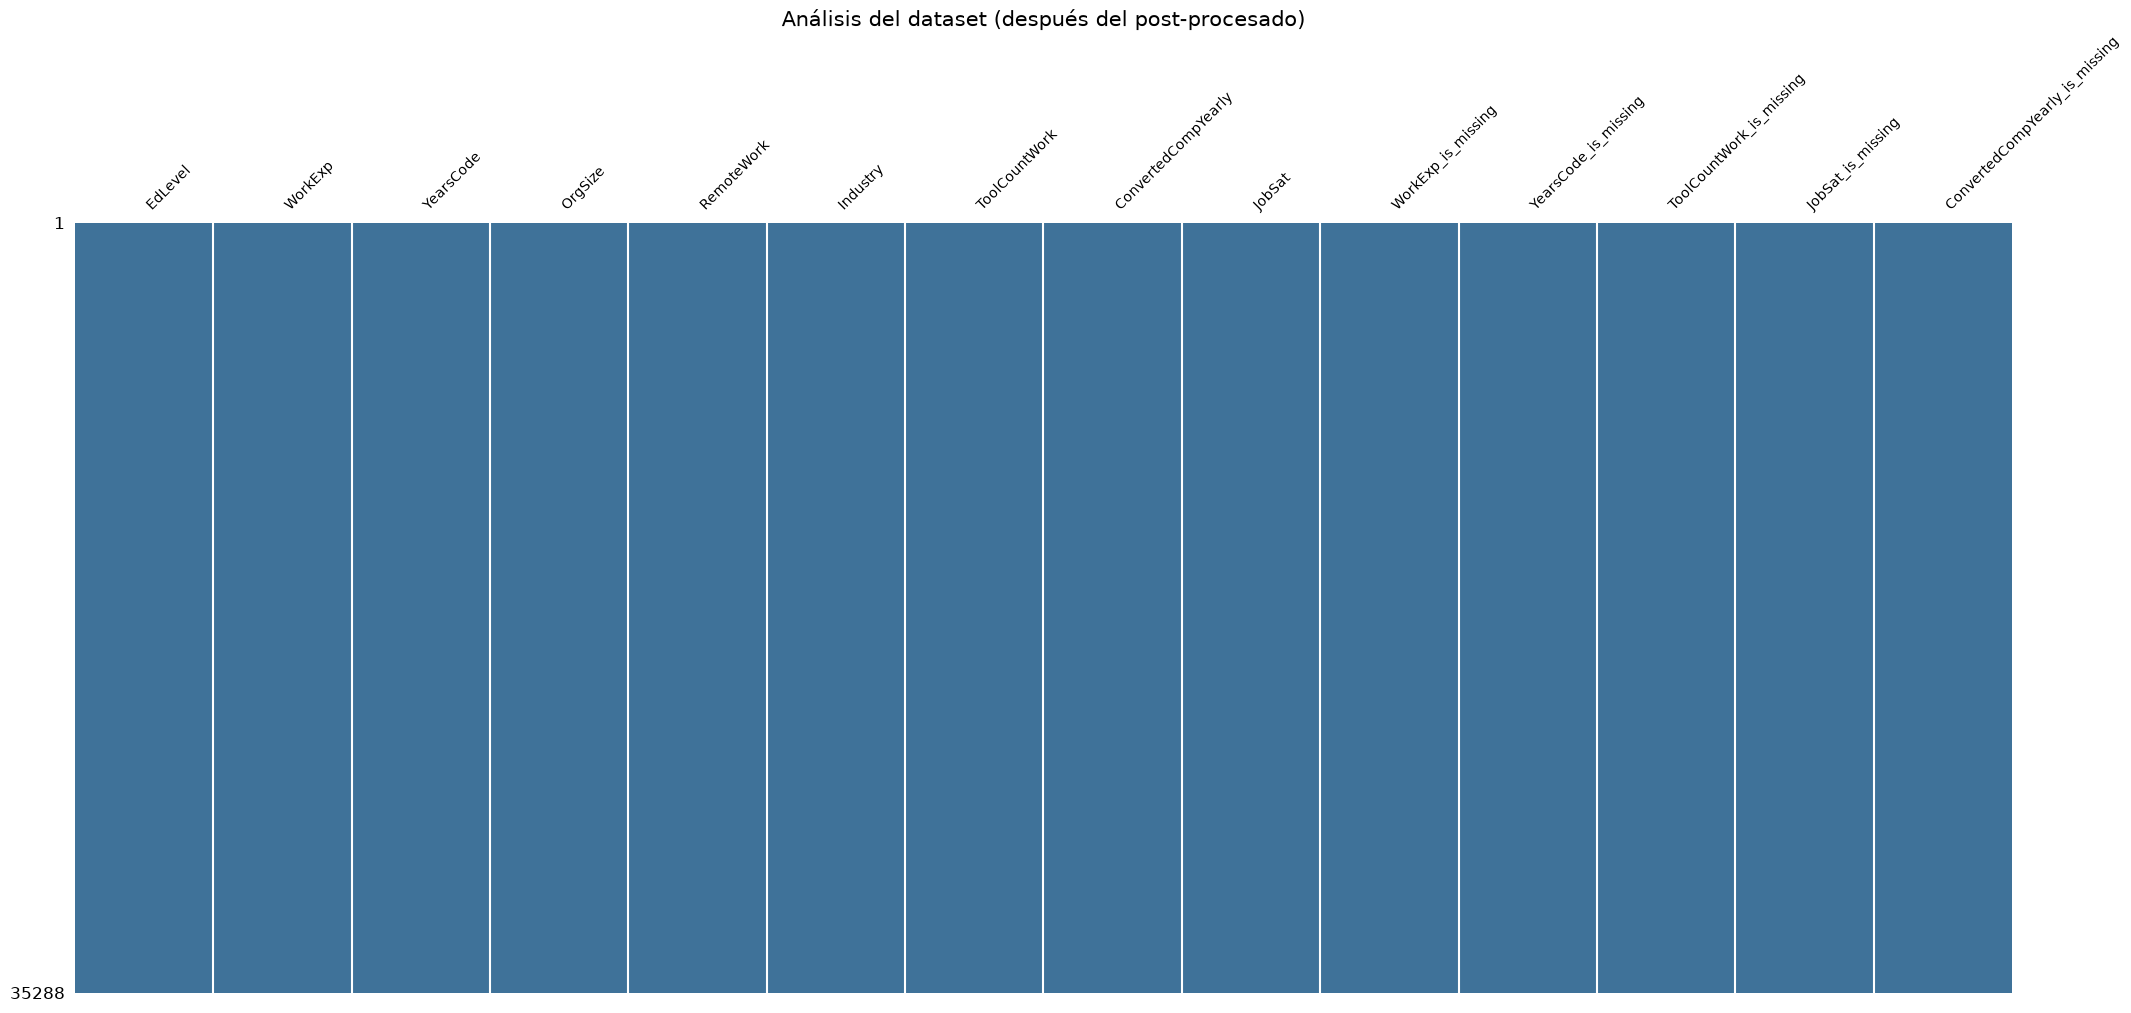

In [6]:
df_numericas = df_feature_engineering.select_dtypes(include=[np.number])

plt.figure(figsize=(10, 5))
msno.matrix(df_numericas, sparkline=False, fontsize=10, color=(0.25, 0.45, 0.6))
plt.title("Análisis del dataset (después del post-procesado)", fontsize=15)
plt.show()

### 2.6. Parseo y binarización de los datos

Las respuestas de la encuesta agrupan los lenguajes, bases de datos y plataformas en una sola cadena de texto separada por caracteres especiales (ej. `Python;SQL;AWS`). 

En este bloque aplicamos nuestra función personalizada `codificar_multilabel` del utils.py para aplicar un *parsing* avanzado y desglosar estas cadenas. Con ella, transformamos cada tecnología en una nueva columna independiente aplicando una **binarización estricta [0, 1]** (1 si el candidato la domina, 0 si no). 

*Nota de optimización:* Hemos aplicado un límite `top_n=20` para conservar únicamente las herramientas más relevantes del mercado, evitando así una explosión de dimensionalidad que aportaría ruido innecesario al modelo.

In [7]:
tech_cols = config.TECH_COLS + ['DevType']

for col in tech_cols:
    if col in df_feature_engineering.columns:
        df_feature_engineering = utils.codificar_multilabel(df_feature_engineering, col, top_n=20)

print(f"Tecnologías binarizadas. Nuevas dimensiones: {df_feature_engineering.shape}")

Tecnologías binarizadas. Nuevas dimensiones: (35288, 209)


### 2.7. Purga de variables y codificación One-Hot

En esta celda refinamos aún más nuestro conjunto de datos antes de pasar a la extracción profunda de tecnologías:

1. **Eliminación de ruido y sesgos:** Descartamos columnas que no nos sirven, como `Zonas_Horarias` ( en este caso por su altísimo nivel de nulos).

2. **One-Hot Encoding:** Para las variables categóricas nominales de alto valor (como el tipo de empleo o si el perfil es *Individual Contributor* o *People Manager*), aplicamos la función `get_dummies`, la cual expande cada categoría en nuevas columnas independientes de ceros y unos `[0, 1]`, manteniendo nuestro ecosistema matemático estrictamente binario y homogéneo.

In [8]:
cols_to_drop = ['Country', 'JobSat', 'JobSat_is_missing', 'Zonas_Horarias']
df_feature_engineering = df_feature_engineering.drop(columns=[col for col in cols_to_drop if col in df_feature_engineering.columns])

cat_cols_nominal = ['Employment', 'ICorPM', 'Continente']
cat_cols_presentes = [col for col in cat_cols_nominal if col in df_feature_engineering.columns]

df_feature_engineering = pd.get_dummies(df_feature_engineering, columns=cat_cols_presentes, dtype=int)

print(f"Dimensiones tras One-Hot Encoding: {df_feature_engineering.shape}")

Dimensiones tras One-Hot Encoding: (35288, 217)


### 2.8. Normalización del espacio matemático con MinMax Scaler

Para que la convergencia de la Red Neuronal sea óptima, todas las variables deben estar referenciadas bajo el mismo estándar. En esta celda aplicamos dos transformaciones clave:

1. **Transformación Logarítmica (`np.log1p`):** Con ella suavizamos la curva de los salarios. El sueldo es una variable con valores atípicos extremos (mucha gente cobrando poco y muy poca cobrando millones), por lo que aplicar un logaritmo estabiliza la métrica y ayuda al modelo a entender la progresión salarial real.

2. **Escalado MinMax:** Comprimimos variables continuas (como años de experiencia, educación o tamaño de la empresa) para meterlas dentro de nuestro estricto rango binario de **[0, 1]**. 

Con esto evitamos el letal **"Sesgo de Magnitud"**: impedimos que el algoritmo asuma erróneamente que "20 años de experiencia" vale 20 veces más que dominar el lenguaje Java (que está representado con un simple 1). 

*El resultado de esta celda es nuestra matriz final*

In [9]:
if 'ConvertedCompYearly' in df_feature_engineering.columns:
    df_feature_engineering['ConvertedCompYearly_Log'] = np.log1p(df_feature_engineering['ConvertedCompYearly'])
    df_feature_engineering = df_feature_engineering.drop(columns=['ConvertedCompYearly'])

cols_to_scale = [
    'WorkExp', 'YearsCode', 'ToolCountWork', 'ConvertedCompYearly_Log',
    'EdLevel', 'RemoteWork', 'OrgSize', 'Industry'
]
cols_to_scale = [col for col in cols_to_scale if col in df_feature_engineering.columns]

scaler = MinMaxScaler()
df_feature_engineering[cols_to_scale] = scaler.fit_transform(df_feature_engineering[cols_to_scale])

print(f"Todo numérico -> {all(df_feature_engineering.dtypes != 'object')}")

df_feature_engineering.to_csv(config.MODEL_MATRIX_PATH, index=True)
print(f"Matriz final guardada en: {config.MODEL_MATRIX_PATH}")
print(f"La red neuronal recibirá {df_feature_engineering.shape[1]} variables (features).")

Todo numérico -> True
Matriz final guardada en: /run/media/miguel-angel/Datos compartidos/TFM/data/processed/matriz_autoencoder.csv
La red neuronal recibirá 217 variables (features).


### 2.9. Proyección 2D (El problema de la baja dimensionalidad)

En esta celda realizamos una primera aproximación con PCA, forzando la reducción de nuestras 217 variables a únicamente 2 dimensiones (PC1 y PC2). El objetivo aquí es intentar ver el ecosistema completo de candidatos en un gráfico plano.

Los resultados devueltos son muy útiles: estas dos componentes principales combinadas apenas logran explicar un **20.4% de la varianza total**. Esto quiere decir, al intentar comprimir el perfil de un desarrollador a solo dos ejes, estamos destruyendo casi el 80% de su información relevante. 

Como podemos observar en la gráfica de dispersión resultante, los perfiles forman una masa densa y entrelazada sin clústeres o fronteras de separación claras. Esto nos demuestra visualmente que el "ADN tecnológico" es un ecosistema ruidoso y altamente complejo que no puede ser clasificado con reglas simples o de forma visual.

Varianza explicada por PC1 y PC2: [0.1644871  0.03980248]
Varianza explicada acumulada: 0.20428957775975345


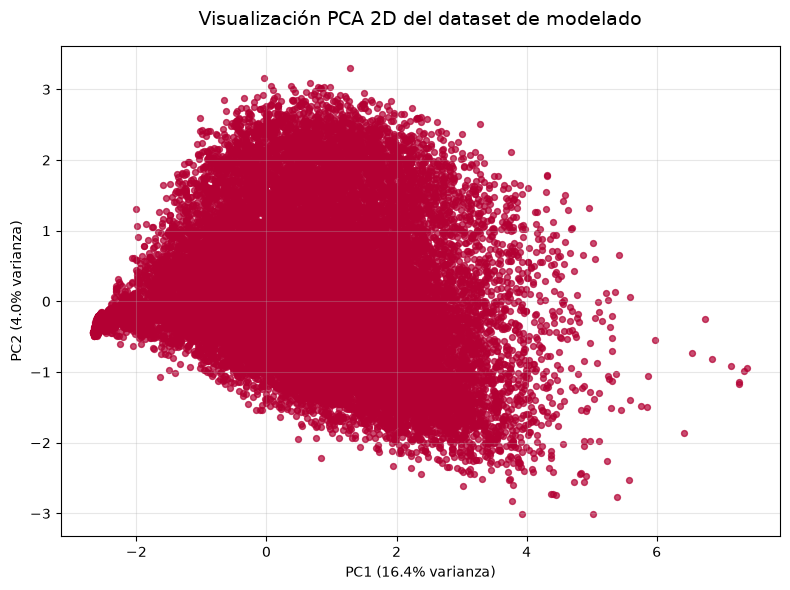

In [10]:
X = df_feature_engineering

pca_2d = PCA(n_components=2, random_state=seed)
X_pca = pca_2d.fit_transform(X)

explained_var = pca_2d.explained_variance_ratio_
print("Varianza explicada por PC1 y PC2:", explained_var)
print("Varianza explicada acumulada:", explained_var.sum())

plt.figure(figsize=(8, 6))
plt.scatter(X_pca.iloc[:, 0], X_pca.iloc[:, 1], s=18, alpha=0.7, color='#B30033')
plt.title("Visualización PCA 2D del dataset de modelado", fontsize=14, pad=15)
plt.xlabel(f"PC1 ({explained_var[0]*100:.1f}% varianza)")
plt.ylabel(f"PC2 ({explained_var[1]*100:.1f}% varianza)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 2.10 Varianza Acumulada y justificación del uso de Deep Learning

En esta celda final aplicamos el PCA sobre todas las dimensiones para estudiar la **varianza explicada acumulada**. El objetivo aquí es ver cuántas dimensiones matemáticas puras necesitamos para conservar el 90% de la información original de los candidatos.
Según vemos en los resultados necesitamos **125 componentes** para retener el 90% de la varianza. 

Al requerir más de la mitad de las variables originales (125 sobre 217) para explicar el ecosistema indica una **complejidad dimensional altísima**. Si utilizáramos algoritmos tradicionales de Machine Learning (como Regresión Logística o Random Forest), sufriríamos la *maldición de la dimensionalidad* y no lograríamos captar las sinergias entre tecnologías. 

Por lo tanto, qpodemos justificar matemáticamente el utilizar **Deep Learning** aquí. De esta forma, podemos aprovechar las redes neuronales profundas y sus funciones de activación no lineales (Autoencoders) que implementaremos en la siguiente fase.

Primeras componentes del PCA:


,Componente,Varianza_Explicada,Varianza_Acumulada
0,1,0.164487,0.164487
1,2,0.039802,0.204290
2,3,0.032455,0.236745
3,4,0.025948,0.262693
4,5,0.022292,0.284986
5,6,0.019403,0.304389
6,7,0.018719,0.323108
7,8,0.016729,0.339837
8,9,0.016223,0.356060
9,10,0.014875,0.370935


Número de componentes necesarios para alcanzar el 90% de varianza: 125
Varianza acumulada retenida con 125 componentes: 0.9010

Comparativa de umbrales:
80% de varianza -> 87 componentes
90% de varianza -> 125 componentes
95% de varianza -> 154 componentes


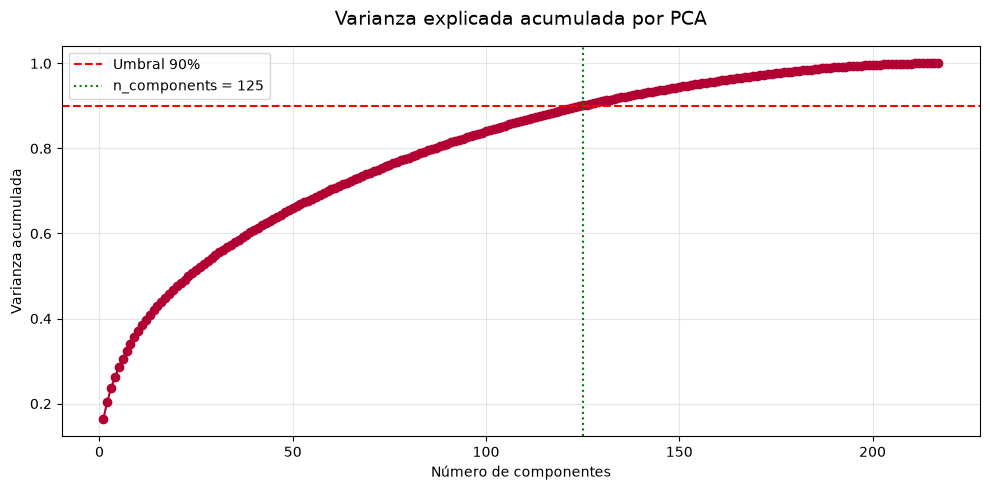

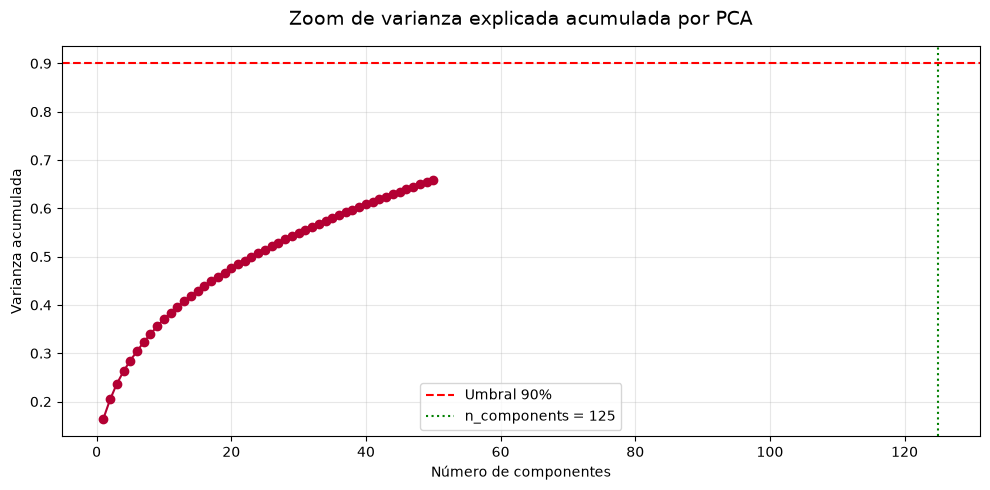

In [11]:
umbral_varianza = 0.90

pca_test = PCA(random_state=seed)
pca_test.fit(X)

varianza_explicada = pca_test.explained_variance_ratio_
varianza_acumulada = np.cumsum(varianza_explicada)

n_opt = np.argmax(varianza_acumulada >= umbral_varianza) + 1

df_pca_varianza = pd.DataFrame({
    "Componente": np.arange(1, len(varianza_explicada) + 1),
    "Varianza_Explicada": varianza_explicada,
    "Varianza_Acumulada": varianza_acumulada
})

print("Primeras componentes del PCA:")
display(df_pca_varianza.head(25))

print(f"Número de componentes necesarios para alcanzar el {int(umbral_varianza*100)}% de varianza: {n_opt}")
print(f"Varianza acumulada retenida con {n_opt} componentes: {varianza_acumulada[n_opt - 1]:.4f}")

print("\nComparativa de umbrales:")
for umbral in [0.80, 0.90, 0.95]:
    n_comp = np.argmax(varianza_acumulada >= umbral) + 1
    print(f"{int(umbral*100)}% de varianza -> {n_comp} componentes")

plt.figure(figsize=(10, 5))
plt.plot(range(1, len(varianza_acumulada) + 1), varianza_acumulada, marker='o', color='#B30033')
plt.axhline(y=umbral_varianza, color='red', linestyle='--', label=f'Umbral {int(umbral_varianza*100)}%')
plt.axvline(x=n_opt, color='green', linestyle=':', label=f'n_components = {n_opt}')
plt.title('Varianza explicada acumulada por PCA', fontsize=14, pad=15)
plt.xlabel('Número de componentes')
plt.ylabel('Varianza acumulada')
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
max_plot = min(50, len(varianza_acumulada))
plt.plot(range(1, max_plot + 1), varianza_acumulada[:max_plot], marker='o', color='#B30033')
plt.axhline(y=umbral_varianza, color='red', linestyle='--', label=f'Umbral {int(umbral_varianza*100)}%')
plt.axvline(x=n_opt, color='green', linestyle=':', label=f'n_components = {n_opt}')
plt.title('Zoom de varianza explicada acumulada por PCA', fontsize=14, pad=15)
plt.xlabel('Número de componentes')
plt.ylabel('Varianza acumulada')
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()